# HW1 — Linear Reservoir Modeling

CEE 306: Hydrology — Water and Climate | Spring 2026


*Portfolio edition:* Original code cells, variable names, comments, and saved outputs are retained from the Spring 2026 coursework notebook. Assignment questions and instructional Markdown have been omitted. Some setup and demonstration code was supplied as part of the course. External NOAA data availability may affect rerunning the final analysis.


**Name:** `Sayfullo Saidov`

## Linear Reservoir Model


### Governing equations and numerical solution


### Numerical simulation setup


In [1]:
# Import modules
import numpy as np
from matplotlib import pyplot as plt

### Time discretization and arrays


In [2]:
# dt is the time step of our simulation
dt = 0.01

# now set up empty arrays using the np.zeros() function - these will be populated with values as the simulation runs
# n_tsteps will represent how many timesteps we want the simulation to run
# to find total physical time of the simulation, multiply dt * n_tsteps
n_tsteps = 1000
total_time = n_tsteps * dt
print(f'The simulation will run for {total_time:.2f} seconds')

# by setting n_steps above, we can ensure that all of the arrays that hold the simulation data will be the same size
# these arrays below hold time, volume (storage), outflow, and rainfall
time = np.zeros(n_tsteps)
V = np.zeros(n_tsteps)
Q = np.zeros(n_tsteps) # flow out of the bucket (solved numerically)
w = np.zeros(n_tsteps) # array for input, rain

# we can check the shape of any of these numpy arrays using np.shape()
print('The shape of the time array is',np.shape(time)[0])

The simulation will run for 10.00 seconds
The shape of the time array is 1000


### Initial conditions


In [3]:
# residence time (again, this is a function of watershed size, soils and geology, slope, and land use)
T_star = 0.1

# initial volume of water (let's say 0)
V_0 = 0

# initial outflow (should therefore be 0)
Q_0 = 0

# set up initial values of storage and  by indexing the array at the first (0) position
V[0] = V_0
Q[0] = Q_0

### Simulated precipitation forcing


In [4]:
## Set up rainfall

# right now, w is all zeros (uncomment line below to check)
print(w)

# but let's say we want a rain flux of 10 for the first 100 timesteps
# then we can manually replace the first 100 timesteps like so
w[0:100] = 10
# again, you can uncomment below to check
print(w)

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.

### Precipitation visualization


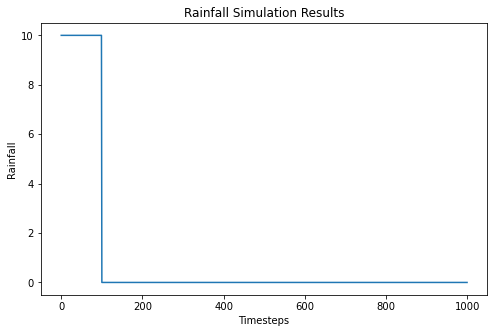

In [5]:
# check rainfall
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(w)
ax.set_ylabel('Rainfall')
ax.set_xlabel('Timesteps') 
ax.set_title('Rainfall Simulation Results')

plt.show()

### Numerical integration


In [6]:
# We re-initialize our arrays here to avoid accidently running the simulation with filled arrays
time = np.zeros(n_tsteps)
V = np.zeros(n_tsteps)
Q = np.zeros(n_tsteps) # flow out of the bucket (solved numerically)
w = np.zeros(n_tsteps) # array for input, rain
V[0] = V_0
Q[0] = Q_0
w[:100] = 10


#start the simulation, using a while loop
# see more info on while loops here: https://www.w3schools.com/python/python_while_loops.asp
# essentially, code will run in the loop until the while condition is reached
# in the loop, we save each value to the ith index (place) of the array. If i = 1, q[i] is q[1]. If i =2, then q[i] = q[2], etc... 

# initialize using a counter 'i'(we already set the values at index 0, so we start at 1)
i = 1

# perform the code below while i is less than the number of time steps
while i < n_tsteps:
    
    # calculate outflow q
    Q[i] = V[i-1]/T_star
    
    # calculate the new volume based on the previous volume and the current w and q
    V[i] = V[i-1] + (w[i]-Q[i])*dt    # we showed how this is derived near the top of the notebook 
    
    # set a lower bound, i.e. V cannot be negative so we reset it to 0 if that's the case 
    if V[i] < 0:
        V[i] = 0
    
    # set the physical time in the simulation
    time[i] = i*dt
    
    # increase the counter by 1 to run this code block again
    i = i+1

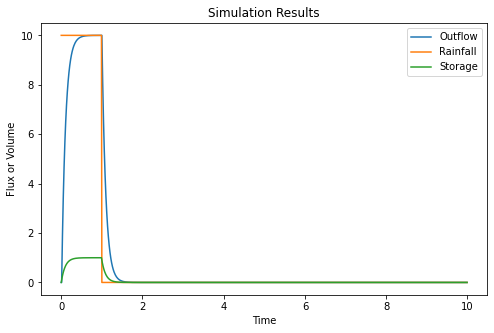

In [7]:
# now let's plot
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(time, Q, label = 'Outflow')
ax.plot(time, w, label = 'Rainfall')
ax.plot(time, V, label = 'Storage')
ax.set_ylabel('Flux or Volume')
ax.set_xlabel('Time') 
ax.set_title('Simulation Results')
plt.legend()
plt.show()

### Simulation results


### Additional plotting examples


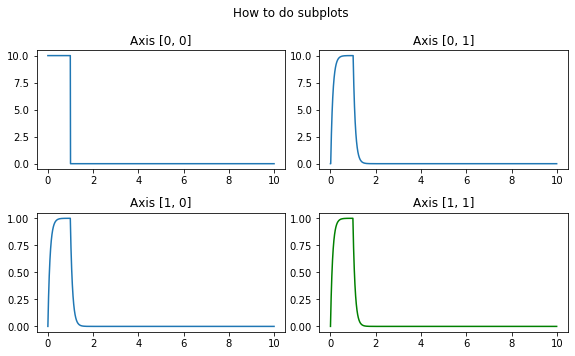

In [8]:
# this plots 4 subplots, arranged in a 2 row x 2 column configuration
fig, axs = plt.subplots(2, 2, figsize=(8,5))
axs[0, 0].plot(time, w)
axs[0, 0].set_title('Axis [0, 0]')
axs[0, 1].plot(time, Q)
axs[0, 1].set_title('Axis [0, 1]')
axs[1, 0].plot(time, V)
axs[1, 0].set_title('Axis [1, 0]')
axs[1, 1].plot(time, V, color='g')
axs[1, 1].set_title('Axis [1, 1]')
fig.suptitle('How to do subplots')
plt.tight_layout()

### Analytical outflow function


In [9]:
import numpy as np

def analytical_q(w, T_star, time):
    return w * (1 - np.exp(-time / T_star))


# Example values
w = 10        # mm/hour
T_star = 5    # hours

times = np.array([0, 1, 2, 5, 10, 20])  # hours

q_values = analytical_q(w, T_star, times)

for t, q in zip(times, q_values):
    print(f"t = {t:>2} h   Q = {q:.3f} mm/h")


t =  0 h   Q = 0.000 mm/h
t =  1 h   Q = 1.813 mm/h
t =  2 h   Q = 3.297 mm/h
t =  5 h   Q = 6.321 mm/h
t = 10 h   Q = 8.647 mm/h
t = 20 h   Q = 9.817 mm/h


## Coursework analysis


### 1. Analytical and numerical solutions


In [10]:
############
# Don't change this cell
############

# define variables
T_star = 0.1
w = 10
t_r = 1
dt = 0.01
n_tsteps = 1000

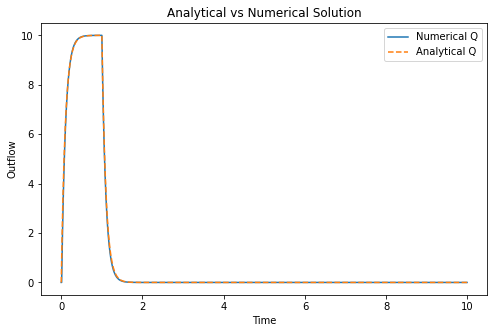

In [11]:
### Answers for Q1 ###

import numpy as np
import matplotlib.pyplot as plt

# Given unchangable parameters
T_star = 0.1
w = 10
t_r = 1
dt = 0.01
n_tsteps = 1000

time = np.arange(n_tsteps) * dt

# Numerical solution (Euler) from above
V = np.zeros(n_tsteps)
Q_num = np.zeros(n_tsteps)
w_array = np.zeros(n_tsteps)

# Rain only for duration t_r
rain_steps = int(t_r/dt) #setting a constant here
w_array[:rain_steps] = w

for i in range(1, n_tsteps):
    Q_num[i] = V[i-1] / T_star
    V[i] = V[i-1] + (w_array[i] - Q_num[i]) * dt
    if V[i] < 0:
        V[i] = 0


# Analytical Solution

#As we learned in class, we need to account for 2 cases: Outflow while it is raining and after it rained#

Q_analytical = np.zeros(n_tsteps)

for i in range(n_tsteps):
    if time[i] <= t_r:
        Q_analytical[i] = w * (1 - np.exp(-time[i]/T_star))
    else:
        Q_tr = w * (1 - np.exp(-t_r/T_star))
        Q_analytical[i] = Q_tr * np.exp(-(time[i]-t_r)/T_star)

# Plot comparison
plt.figure(figsize=(8,5))
plt.plot(time, Q_num, label="Numerical Q")
plt.plot(time, Q_analytical, '--', label="Analytical Q")
plt.xlabel("Time")
plt.ylabel("Outflow")
plt.title("Analytical vs Numerical Solution")
plt.legend()
plt.show()

Q1 `The numerical and analytical solutions match almost perfectly, very closely. Overllaping two graphs, it is noticeable. Shortly, the difference comes from the Euler's method of approximating the differential equation using very small steps, while the analytical solution just does the continuous math, giving the exact exponential formula. I believe as dt is small, the numerical solution in this case is also accurate. So both ways are representing the linear reservoir model similarly`

### 2. Effects of reservoir response time


Text(0.5, 1.0, 'Rainfall')

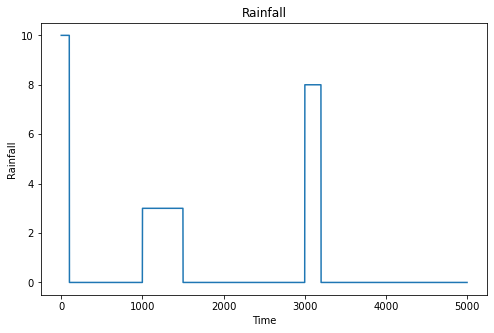

In [33]:
############
# Don't change this cell, but make sure you understand it
############

# set time step and number of time steps for the simulation
dt = 0.01
n_tsteps = 5000
total_time = n_tsteps * dt

# create a time matrix (since we want our x-axis in units of T, not 0.01T)
time = np.arange(n_tsteps)*dt

# create rainfall matrix defining variable rainfall
w = np.zeros(n_tsteps)
w[:100] = 10
w[1000:1500] = 3
w[3000:3200] = 8

# visualize rainfall
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(w)
ax.set_ylabel('Rainfall')
ax.set_xlabel('Time') 
ax.set_title('Rainfall')

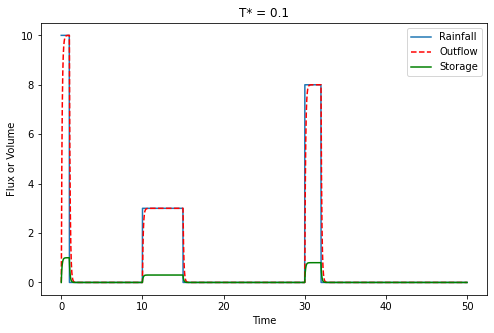

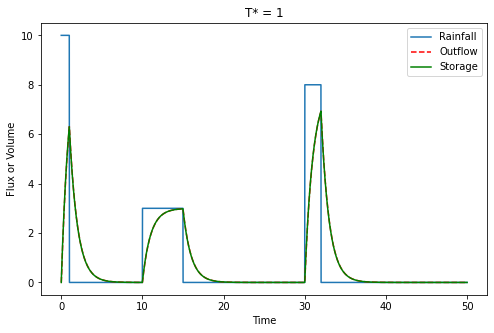

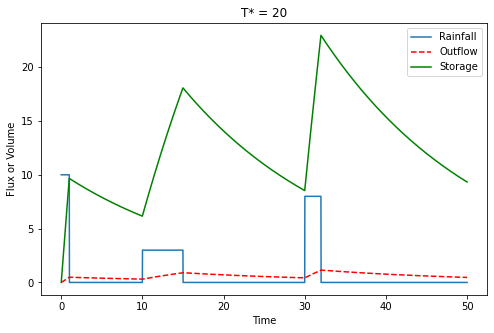

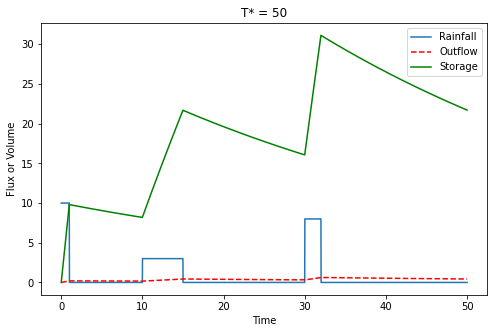

In [35]:
### your Q2 code goes here ###

#recopying the numerical solution function from the previous steps:

def linear_reservoir(T_star, w, dt, n_tsteps):
    V = np.zeros(n_tsteps)
    Q = np.zeros(n_tsteps)
    
    for i in range(1, n_tsteps):
        Q[i] = V[i-1] / T_star
        V[i] = V[i-1] + (w[i] - Q[i]) * dt
        if V[i] < 0:
            V[i] = 0
    return Q, V

#In this second question, I will plot 4 graphs to see how changing T* affects the other parameters:

T_values = [0.1, 1, 20, 50]

for T_star in T_values:
    Q, V = linear_reservoir(T_star, w, dt, n_tsteps)
    
    plt.figure(figsize=(8,5))
    plt.plot(time, w, label="Rainfall")
    plt.plot(time, Q, '--', label="Outflow", color = 'red')
    plt.plot(time, V, label="Storage", color = 'green')
    plt.title(f"T* = {T_star}")
    plt.xlabel("Time")
    plt.ylabel("Flux or Volume")
    plt.legend()
    plt.show()

    #For T* = 1, V = Q from the formula, so green and red are overlapping. 

### 3. Interpretation of response time


Q3.1 `As T* (response time) increases, the system responds more slowly. For small T* (0.1): Outflow rises quickly, Peaks quickly, Storage remains small and hits the maximum instantly, Fast recession, immediate draining. For T* = 1: Outflow equals the Storage. So it is very smooth process and can be taken as a reference to compare smaller T* and larger T* values than 1. For large T* (20, 50): Outflow increases slowly. Broader hydrograph. Storage becomes much larger. Slow recession. Outflow barely responds to the rainfall and stays mostly flat. In conclusion, increasing T* increases storage and spreads discharge over longer time.`

Q3.2 `Watershed response time depends on several aspects. Some factors are: Basin size (larger basin means larger T*), Slope (steeper → smaller T*, meaning faster drainage), Soil permeability (more permeable → larger T*), Land use (if urban → smaller T*), Presence of wetlands or lakes nearby. Small T* represents flashy, sandy, urban, steep watersheds. Large T* represents flat, wild, clay, permeable basins.`

### 4. Observed precipitation and streamflow comparison


In [37]:
############
# Don't change this cell, but make sure you understand it
############

# import pandas
import pandas as pd

# read in precip data from franklin
url = "https://www.ncei.noaa.gov/access/services/data/v1?dataset=daily-summaries&dataTypes=PRCP&stations=US1NJSM0091&startDate=2022-01-01&endDate=2022-01-06&units=standard"
# note that this url ends in 'units=standard', meaning precip will be in inches
franklin_precip = pd.read_csv(url, skiprows=0)

# read in Stony Brook streamflow data
start_date = "2022-01-01"
end_date = "2022-01-06"
site_no = "01401000"
url = f'https://waterservices.usgs.gov/nwis/dv/?format=rdb&sites={site_no}&startDT={start_date}&endDT={end_date}&siteStatus=all' 
StonyBrook_streamflow = pd.read_csv(url, skiprows=29, sep='\t', header=None)
StonyBrook_streamflow.columns=['agency','station','datetime','flow','id']
print(url)
# we now have two dataframes
# franklin precip is in inches/day
# but stony brook is in cfs, so we need to convert stony brook outflow from mean cfs to mean in/day

# conversions
area = 44.5*2.788e7 # square feet
inches_per_foot = 12 # inches
seconds_per_day = 60*60*24 # seconds

# create new inches_per_day column
StonyBrook_streamflow['flow_in_per_day'] = StonyBrook_streamflow['flow']*inches_per_foot*seconds_per_day/area

# print both datasets (only 6 days)
print(franklin_precip)
print(StonyBrook_streamflow)

####
# note that our units are now in L/T not L^3/T
# we could have also converted precip to L^3/T and left flow as is
# as long as we are consistent with units, either is fine
####

https://waterservices.usgs.gov/nwis/dv/?format=rdb&sites=01401000&startDT=2022-01-01&endDT=2022-01-06&siteStatus=all
       STATION        DATE  PRCP
0  US1NJSM0091  2022-01-01  0.08
1  US1NJSM0091  2022-01-02  1.05
2  US1NJSM0091  2022-01-03  0.00
3  US1NJSM0091  2022-01-04  0.00
4  US1NJSM0091  2022-01-05  0.00
5  US1NJSM0091  2022-01-06  0.06
  agency  station    datetime   flow id  flow_in_per_day
0   USGS  1401000  2022-01-01   50.1  A         0.041868
1   USGS  1401000  2022-01-02  661.0  A         0.552387
2   USGS  1401000  2022-01-03  117.0  A         0.097775
3   USGS  1401000  2022-01-04   72.1  A         0.060253
4   USGS  1401000  2022-01-05   59.4  A         0.049640
5   USGS  1401000  2022-01-06   55.8  A         0.046631


In [38]:
############
# Don't change this cell, but make sure you understand it
############


# define dt (in days)
dt = 0.01

# define number of time steps (unitless) so that we use all 6 days of data from above cell
n_tsteps = int(6/dt) # Now each day is equivalent to 100 time-steps
print(f'Number of time steps in a day = {n_tsteps} / 6 days = {n_tsteps/6}')

# define T_star
T_star = 0.75

# initialize empty arrays for time, rain, volume, and outflow
time = np.zeros(n_tsteps)
V = np.zeros(n_tsteps)
q = np.zeros(n_tsteps)
w = np.zeros(n_tsteps)
q_stony = np.zeros(n_tsteps) #streamflow recorded at Stony Brook

# define an ET (evapotranspiration) factor to convert w to an effective w
ET_factor = 0.8
# this essentially assumes 20% of rainfall is evaporated/ transpirated and doesn't make it to Stony Brook
# we will get into ET later in the course

Number of time steps in a day = 600 / 6 days = 100.0


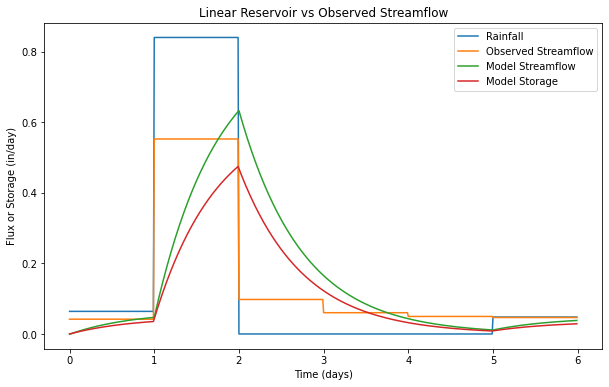

In [39]:
### your Q4.1 code goes here ###
### suggested steps are provided ###


# FIRST: fill in the w matrix corresponding based on the franklin_precip dataframe and the ET factor:
# for example, for all 100 timesteps within day 1, rainfall is equal to 0.08 in/day * ET factor



# SECOND: fill q_stony (Stony Brook outflow) with values of 'flow_in_per_day' from the StonyBrook_streamflow dataframe
# for example, for all 100 timesteps within day 1, outflow is equal to 0.552387 in/day


# THIRD: run the simulation to calculate q *numerically*



# FOURTH: plot the results, which should include:
# - actual rainfall at franklin
# - actual streamflow at Stony Brook
# - model output streamflow (q)
# - model output storage (V)



# FIRST: Filling rainfall matrix for 6 entries that we have:

#There are 0 to 5, so the total number is 6 indexes. Taking each precipitation from every day and multiplying with ET factor. 
for day in range(6):
    daily_rain = franklin_precip["PRCP"][day] * ET_factor
    w[day*100:(day+1)*100] = daily_rain

# SECOND: Filling observed streamflow of Stony brook

#dt divides day into 100 parts. That's why accounting for it with day*100 in a matrix. First day is 0:100, second day is 100:200, etc.

for day in range(6):
    daily_flow = StonyBrook_streamflow["flow_in_per_day"][day]
    q_stony[day*100:(day+1)*100] = daily_flow

# THIRD: Running numerical simulation (same code from previous examples)#
for i in range(1, n_tsteps):
    q[i] = V[i-1] / T_star
    V[i] = V[i-1] + (w[i] - q[i]) * dt
    if V[i] < 0:
        V[i] = 0
    time[i] = i*dt

# FOURTH: Plot results
plt.figure(figsize=(10,6))
plt.plot(time, w, label="Rainfall")
plt.plot(time, q_stony, label="Observed Streamflow")
plt.plot(time, q, label="Model Streamflow")
plt.plot(time, V, label="Model Storage")
plt.xlabel("Time (days)")
plt.ylabel("Flux or Storage (in/day)")
plt.legend()
plt.title("Linear Reservoir vs Observed Streamflow")
plt.show()



Q4.2 `On one plot, I plotted four different graphs. It is easy to differentiate the observed vs. model output. Firstly, the similarity is a large increase in outflow on January 2nd, following a rain event. Both model and observed data show a large spike. Secondly, the differences are also noticeable. The observed streamflow seems like sharper, while the model produces smoother hydrograph. The magnitude is obviously showing a bit of difference in the actual values. However, these are understandable reasons.`

` 1. The linear reservoir is a very simplified one-box model. 2. In reality, watersheds usually have multiple pathways and multiple storage places. Those are snowmelt, groundwater infiltration, and some channel routing that are considered redundant in linear reservoir model. Another big factor that was added in the fucntion was ET factor. 0.8 is also a rough estimate, and the reality is much more complex. T* is also constant in the model and not calibrated while the actual watershed would incorporate several response times across different parts. While linear reservoir model might be limited for precise prediction, it is doing relatively a nice job relying only on one T* value. So, it can be used theoretically in this case. `

### Acknowledgement 
`I used AI for trying out the for loop instead of the while loop in above exercises`